# Exact point defect model

A B2 intermetallic that is stable over a range of compositions, because atoms can swap between its two sublattices or leave vacancies behind. Each defect is described by its formation energy alone, the natural output of a DFT supercell calculation.

The compound competes with terminal solid solutions and a liquid, using the same model as the landau `PointDefects` example notebook.

Writes `Point_Defects_Exact.svg`/`.png` (transparent) next to the notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from landau import IdealSolution, LinePhase, plot_phase_diagram
from landau.calculate import calc_phase_diagram
from landau.phases import kB
from landau.phases.pointdefects import ConstantPointDefect, PointDefectedPhase, PointDefectSublattice

In [2]:
OUT = "Point_Defects_Exact.svg"

FIGSIZE = (6.4, 4.8)
FONTSIZE = 13
DPI = 200

## B2 compound

A stoichiometric AB host with one A and one B sublattice, each holding half of the sites.

| Defect | Sublattice | $E_i$ (eV) | $[n_i]$ |
|--------|------------|-----------|--------|
| B$_\alpha$ antisite | $\alpha$ (A sites) | 0.28 | +1 |
| V$_\alpha$ vacancy  | $\alpha$ (A sites) | 0.45 | +½ |
| A$_\beta$ antisite  | $\beta$ (B sites)  | 0.30 | −1 |
| V$_\beta$ vacancy   | $\beta$ (B sites)  | 0.50 | −½ |

In [3]:
host = LinePhase("AB", fixed_concentration=0.5, line_energy=-0.40, line_entropy=1.0 * kB)

B_alpha = ConstantPointDefect("B_alpha", excess_energy=0.28, excess_entropy=0, excess_solutes=+1)
V_alpha = ConstantPointDefect("V_alpha", excess_energy=0.45, excess_entropy=0, excess_solutes=+0.5)
A_beta = ConstantPointDefect("A_beta", excess_energy=0.30, excess_entropy=0, excess_solutes=-1)
V_beta = ConstantPointDefect("V_beta", excess_energy=0.50, excess_entropy=0, excess_solutes=-0.5)

eta = 0.5  # sites per atom on each sublattice
ab_exact = PointDefectedPhase(
    name="AB",
    line_phase=host,
    sublattices=[
        PointDefectSublattice(name="alpha", sublattice=0, sublattice_fraction=eta, defects=[B_alpha, V_alpha]),
        PointDefectSublattice(name="beta", sublattice=1, sublattice_fraction=eta, defects=[A_beta, V_beta]),
    ],
)

## Competing phases

Terminal solid solutions bracket the compound; a liquid appears at high temperature.

In [4]:
solid = IdealSolution("solid",
    LinePhase("A", fixed_concentration=0, line_energy=-0.33, line_entropy=1.0 * kB),
    LinePhase("B", fixed_concentration=1, line_energy=-0.30, line_entropy=1.0 * kB))
liquid = IdealSolution("liquid",
    LinePhase("A(l)", fixed_concentration=0, line_energy=-0.10, line_entropy=3.3 * kB),
    LinePhase("B(l)", fixed_concentration=1, line_energy=-0.13, line_entropy=3.3 * kB))

## Phase diagram

In [5]:
df = calc_phase_diagram([solid, liquid, ab_exact], Ts=np.linspace(200, 1400, 25), mu=np.linspace(-0.8, 0.8, 200))

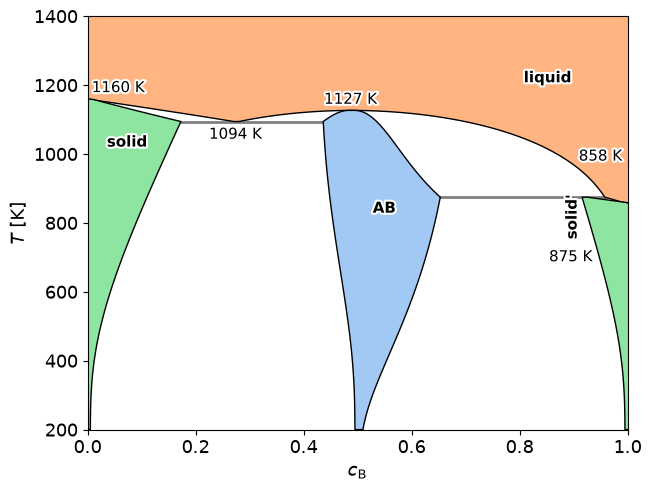

In [6]:
plt.style.use("default")
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})
fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")

plot_phase_diagram(df, triplepoints=True, transition_temperatures=True, ax=ax)
ax.set_xlim(0, 1)
ax.set_ylim(200, 1400)
ax.set_xlabel("$c_\\mathrm{B}$")

fig.savefig(OUT)
fig.savefig(OUT.replace(".svg", ".png"), dpi=DPI, transparent=True)